In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import tensorflow as tf
from tensorflow import keras
import scipy
from sklearn.model_selection import train_test_split as tts
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import accuracy_score , recall_score , confusion_matrix , precision_score

In [2]:
PARTIENCE = 50
EPOCH = 500
DROPOUT = 0.01
LEARNING_RATE = 3e-4
FACTOR = 0.4

In [3]:
df = pd.read_csv(".\\Data.csv")
print(df.head(5))

x_str = df[["smoker_status", "chest_pain_type", "sex"]]
x_smoker_status = df.drop(["smoker_status"] ,axis=1)
chest_pain_type = x_smoker_status.drop(["chest_pain_type"] ,axis=1)
x_sex = chest_pain_type.drop(["sex"] ,axis=1)
x = x_sex.drop(["has_heart_disease"] , axis=1)
y = df["has_heart_disease"]

from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config
set_config(transform_output="default")
ohe = OneHotEncoder(sparse_output=False)
x_str = ohe.fit_transform(x_str)

x = x.values.astype(np.float32)
y = y.values.astype(np.float32)
x_str = x_str.astype(np.float32)
x = np.hstack([x, x_str])
y = np.array(y)

y.reshape(-1,1)
x.reshape(-1, 1)


X_train , X_test , Y_train , Y_test = tts(x ,y ,test_size=0.3)
X_test , X_val , Y_test ,Y_val = tts(X_test ,Y_test ,test_size=0.5)
INPUT_DIM = X_train.shape[1]
print(X_train.shape , X_test.shape , Y_train.shape , Y_test.shape)

   age     sex  resting_bp_systolic  resting_bp_diastolic  cholesterol_total  \
0   44    Male                  117                    74                193   
1   57    Male                  139                    94                185   
2   29    Male                  128                    78                197   
3   72    Male                  132                    86                197   
4   62  Female                  116                    75                154   

   hdl  ldl  triglycerides  fasting_blood_sugar  hba1c  ...  family_history  \
0   57  106            119                  112    5.2  ...           False   
1   69  110             35                  114    5.9  ...           False   
2   52  108            157                   95    5.5  ...           False   
3   59  104            143                   92    4.8  ...           False   
4   65   75            104                  135    6.2  ...            True   

   smoker_status  alcohol_units_per_week exe

In [4]:
model_rf = RandomForestClassifier()
model_rf.fit(X_train ,Y_train)
feature = model_rf.feature_importances_
print(feature)

[0.04547694 0.03018678 0.02204599 0.0288976  0.04038323 0.04806368
 0.02363667 0.03053356 0.02788115 0.03454898 0.02337412 0.24073634
 0.11534643 0.07499806 0.00438706 0.02288173 0.0315827  0.02166384
 0.02622221 0.00404537 0.0270365  0.02927141 0.00871682 0.00296993
 0.00583136 0.00588475 0.00358781 0.00307782 0.00731512 0.00496122
 0.00445481]


In [6]:
def creat_model():
    model = tf.keras.Sequential([
    tf.keras.layers.Dense(units=INPUT_DIM , activation="relu", input_shape=[INPUT_DIM]),
    tf.keras.layers.Dense(units=16 , activation="relu"),
    tf.keras.layers.Dense(units=8 , activation="relu"),
    tf.keras.layers.Dropout(0.1),    
    tf.keras.layers.Dense(units=1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PARTIENCE ,verbose=2  ,restore_best_weights=True )
    reduce = keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=FACTOR ,min_lr=LEARNING_RATE)
    global his
    his = model.fit(X_train , Y_train, epochs=EPOCH , validation_data=(X_test , Y_test), callbacks=[early, reduce])
    return model

model = creat_model()

Epoch 1/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6862 - loss: 2.9781 - val_accuracy: 0.6889 - val_loss: 0.5996 - learning_rate: 0.0010
Epoch 2/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6997 - loss: 0.6036 - val_accuracy: 0.6881 - val_loss: 0.5981 - learning_rate: 0.0010
Epoch 3/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6998 - loss: 0.6021 - val_accuracy: 0.6881 - val_loss: 0.5943 - learning_rate: 0.0010
Epoch 4/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7000 - loss: 0.5945 - val_accuracy: 0.6874 - val_loss: 0.5859 - learning_rate: 0.0010
Epoch 5/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6998 - loss: 0.5851 - val_accuracy: 0.6874 - val_loss: 0.5669 - learning_rate: 0.0010
Epoch 6/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7005 - loss: 0.5615 - val_accuracy: 0.6874 - val_loss: 0.5349 - learning_rate: 0.0010
Epoch 7/500
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6998 - loss: 0.

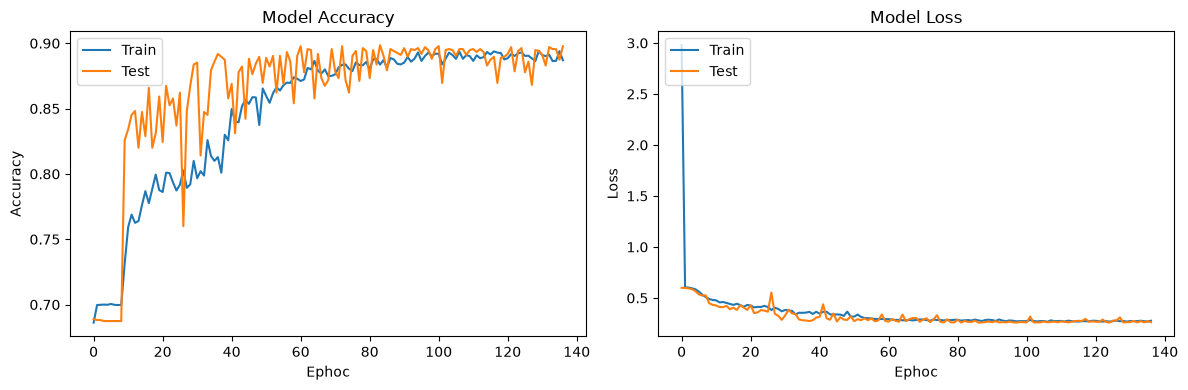

In [7]:
plt.figure(figsize=(12, 4))
plt.subplot(1 , 2 , 1)
plt.plot(his.history["accuracy"])
plt.plot(his.history["val_accuracy"])
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Ephoc")
plt.legend(["Train" , "Test"] , loc="upper left")

plt.subplot(1 , 2 , 2)
plt.plot(his.history["loss"])
plt.plot(his.history["val_loss"])
plt.title("Model Loss")
plt.ylabel("Loss")
plt.xlabel("Ephoc")
plt.legend(["Train" , "Test"] , loc="upper left")

plt.tight_layout()
plt.show()

In [8]:
pred = model.predict(X_test)
pred_train = model.predict(X_train)

a = accuracy_score(Y_test , pred.round())
at = accuracy_score(Y_train , pred_train.round())
r = recall_score(Y_test , pred.round())
c = confusion_matrix(Y_test , pred.round())
p = precision_score(Y_test , pred.round())
a ,at, c , p , r

43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


(0.8955555555555555,
 0.8995238095238095,
 array([[871,  57],
        [ 84, 338]]),
 0.8556962025316456,
 0.8009478672985783)

In [9]:
config = {
    "INPUT_DIM" : X_train.shape[1],
    "PARTIENCE" : 50,
    "EPOCH" : 500,
    "DROPOUT" : 0.01,
    "LEARNING_RATE" : 3e-4,
    "FACTOR" : 0.4
}

with open("Model.pkl", "wb") as f:
    pickle.dump(model ,f)
with open("Config.pkl", "wb") as f:
    pickle.dump(config ,f)    

with open("OneHotEncoder.pkl", "wb") as f:
    pickle.dump(ohe ,f)